## 케라스 (KEras)

- 딥러닝 모델을 쉽고 빠르게 만들 수 있도록 도와주는 고수준 딥러닝
- 텐서플로(Tensorflow) 위에서 동작하며, 복잡한 수학적 계산을 직접 구현하지 않고 모델 구성
및 학습 가능
- 작업 흐름
    1. 모델 정의
    2. 컴파일
    3. 학습

### 환경 준비 : tensorflow 설치
```bash
pip install tensorflow
최신 버전 설치 후 동작 불가 시 버전 지정하여 설치

pip uninstall tensorflow

pip install tensorflow==2.15.1
```

In [39]:
import os
import tensorflow as tf

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3" # 정보성 로그(WARNING) 제거

tf.__version__

'2.15.1'

In [40]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# from tensorflow.keras import Sequential         # 표준으로 사용되는 방식
from keras import Sequential                      # 공식 권장 방식 ---> 하나로 통일하여 사용할 것!
from keras.layers import Dense, Dropout, Input
from keras.callbacks import EarlyStopping

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, accuracy_score

import _ml
from _style import setup

SEED = _ml.SEED
setup()

print("준비 완료")

준비 완료


---

머신러닝으로는 `오늘 오를까?`를 예측했고, 결과는 AUC 0.5 부근으로 사실상 랜덤이었음.
신호가 없는 문제로는 **알고리즘이 잘 동작하는지조차 확인할 수 없었음**

딥러닝으로는 `오늘 거래량이 최근 20일 평균보다 많을까?`를 예측해보기. (거래량 급증 여부)

거래량은 한 번 몰리면 며칠 이어지는 성질이 있어 **어느정도 예측이 가능할 것임!**

In [41]:
def load_datasets():
    """
        거래량 급증 예측용 데이터셋을 만들어서 반환

        - 기존 피처(_ml.FEATURES) 7개에 2개를 추가(volume_prev, 전일 거래량) (close_prev, 전일 종가)
        - 정답 (surge) : 오늘 거래량이 직전 20일 평균 거래량보다 크면 1, 아니면 0
    """
    # 기존 데이터셋에서 피처 2개 추가
    base = _ml.build_dataset().sort_values(["code", "date"])

    base["volume_prev"] = base.groupby("code")["volume"].shift(1)
    base["close_prev"] = base.groupby("code")["close"].shift(1)

    # 원본 데이터에서 계산 후 정답 추가
    raw = _ml.load_merged().sort_values(["code", "date"])

    # - 정답 : 오늘 거래량 > 직전 20일 평균 거래량

    # 직전 20일 평균 거래량
    raw["vol_ma20_prev"] = raw.groupby("code")["volume"].transform(lambda s: s.rolling(20).mean().shift(1))

    # 정답 (surge) : 거래량 급증 여부 (1: 급증, 0: 아님)
    raw["surge"] = (raw["volume"] > raw["vol_ma20_prev"]).astype("int8")

    df = base.merge(raw[["code", "date", "surge"]], how="left", on=["code", "date"])
    return df.dropna(subset=["volume_prev", "close_prev", "surge"]).reset_index(drop=True)

df = load_datasets()
FEATURES = _ml.FEATURES + ["volume_prev", "close_prev"]


print(f"데이터 {len(df):,}행, 피처 {len(FEATURES)}개")
print(f"급증 비율 : {df['surge'].mean():.3f}")
print(f"피처 : {FEATURES}")


데이터 87,360행, 피처 9개
급증 비율 : 0.366
피처 : ['ret_1d', 'ret_5d', 'ma5_ratio', 'ma20_ratio', 'vol20', 'volume_ratio', 'range_pct', 'volume_prev', 'close_prev']


In [42]:
# 시계열 데이터는 시간순으로 분할 (데이터 분리 -> 훈련용, 검증용)
train, test, cutoff = _ml.time_split(df, test_size=0.2)

# X(피처, 입력), y(타깃, 정답) 분리
X_train = train[FEATURES].to_numpy("float32")
y_train = train["surge"].to_numpy("float32")

X_test = test[FEATURES].to_numpy("float32")
y_test = test["surge"].to_numpy("float32")

print(f"분할 기준일: {cutoff.date()}")
print(f"학습 : {X_train.shape}  검증 : {X_test.shape}")

scale = pd.DataFrame({
    "평균": X_train.mean(axis=0),
    "표준편차": X_train.std(axis=0),
    "최대": X_train.max(axis=0)
}, index=FEATURES)

print()
print(scale.to_string(float_format=lambda v: f"{v:>18,.4f}"))
print(f"표준편차 최대/최소 = {scale['표준편차'].max() / scale['표준편차'].min():,.0f} 배 차이")

분할 기준일: 2026-01-16
학습 : (69960, 9)  검증 : (17400, 9)

                             평균               표준편차                 최대
ret_1d                  -0.0003             0.0263             0.2755
ret_5d                  -0.0014             0.0613             0.4257
ma5_ratio                0.9989             0.0298             1.2395
ma20_ratio               0.9950             0.0687             1.4317
vol20                    0.0243             0.0101             0.0677
volume_ratio             1.0016             0.9528            15.5041
range_pct                4.3529             2.0448            33.7038
volume_prev        577,769.7500     1,555,611.6250    71,626,144.0000
close_prev          46,903.8906        59,168.6992       552,685.0000
표준편차 최대/최소 = 154,746,496 배 차이


현재 표준 편차가 **1억 배 이상** 차이나는 상태로 확인됨.\
이 상태로 신경망에 입력하면, 거대한 피처가 기울기 계산을 독점하게 될 것임.\
--> 학습이 제대로 되지 않기 때문에, 표준화 또는 정규화의 전처리가 필수적임!
---

### 딥러닝의 3단계 : 모델 정의 -> 컴파일 -> 학습

1. 모델 정의 : 어떤 층을 어떻게 쌓을 것인가?
2. 컴파일 : 무엇을 최소화하고 어떻게 학습할 것인가?
3. 학습 : 데이터를 넣고 반복

케라스(keras)를 사용하면 통일된 형태로 간단하게 구현이 가능함!

In [43]:
def build_model(n_features, hidden=(64, 32), dropout=0.0):
    """
        이진 분류용 신경망 생성

        매개변수
            n_features  : 입력 피처 개수
            hidden      : 은닉층 뉴런수. 튜플의 길이가 은닉층 개수 (기본 64, 32 두 층)
            dropout     : 0보다 큰 경우 각 은닉층 뒤에 Dropout을 추가 (비율, 0~1)
        
        반환값
            model       : 컴파일까지 끝난 Sequential 모델
    """

    # 가중치 초기값 고정. (동일한 데이터로 사용하도록 설정)
    tf.keras.utils.set_random_seed(SEED)

    layers = [ Input(shape=(n_features, )) ]    # 입력층 (입력 벡터의 크기 -> 피처 개수)

    for units in hidden:
        layers.append(
            Dense(units, activation="relu")    # 은닉층 (활성화 함수 : 계산이 단순하고 비선형 표현)
        )
        if dropout > 0:
            layers.append( Dropout(dropout) )

    layers.append( Dense(1, activation="sigmoid") )   # 이진분류 -> 출력 1개 + sigmoid

    model = Sequential(layers)      # [1] 모델 정의 ----- *

    # [2] 컴파일
    model.compile(
        optimizer="adam",               # 파라미터별로 학습 속도를 적응적으로 조절하는 최적화 방법
        loss="binary_crossentropy",     # 손실함수 -> 오차를 측정하는 기준
        metrics=["accuracy"]            # 정확도(accuracy) 기록 설정
    )

    return model

model = build_model(len(FEATURES))
model.summary()

Model: "sequential_12"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_36 (Dense)            (None, 64)                640       
                                                                 
 dense_37 (Dense)            (None, 32)                2080      
                                                                 
 dense_38 (Dense)            (None, 1)                 33        
                                                                 
Total params: 2753 (10.75 KB)
Trainable params: 2753 (10.75 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


**Total params** : Dense 층의 파라미터는 (입력개수 * 뉴런개수) + 뉴런개수(편향) 임.

dense 9x64+64 = 640\
dense_1 64x32+32 = 2080\
dense_2 32X1+1 = 33\
= 2753

Dense(64) 한 줄로 가중치 576개와 편향 64개가 알아서 만들어진 것임!\
Dropout 층은 파라미터가 없고, 파라미터 수는 데이터 행 수와 무관하게 모델 구조로만 정해짐.

---
### 학습 곡선을 그리는 함수 정의

In [44]:
def plot_history(hist, title, ax=None, ylim=None):
    """
        학습 곡선을 그리는 함수

        매개변수
            hist    : model.fit() 이 반환한 History 객체.
            title   : 차트 제목
            ax      : 그래프를 그릴 영역 객체(Axes). None인 경우 새로 생성.
            ylim    : y축 범위 (최솟값, 최댓값).
        
        반환값
            ax      : 학습 곡선이 그려진 그래프 객체 (Axes)
    """

    if ax is None:
        _, ax = plt.subplots(figsize=(8,4))

    if ylim:
        ax.set_ylim(*ylim)

    # * loss : 훈련 데이터 오차
    # * val_loss : 검증 데이터 오차

    epochs = range(1, len(hist.history['loss']) + 1)

    ax.plot(epochs, hist.history['loss'], label="train", lw=1.6)
    ax.plot(epochs, hist.history['val_loss'], label="validation", lw=1.6)

    # 검증 소실이 가장 낮았던 지점
    best = int(np.argmin(hist.history['val_loss'])) + 1

    ax.axvline(best, color="gray", ls=":", lw=1)

    ax.set(xlabel="에포크", ylabel="손실", title=title)
    ax.legend()

    return ax

def evaluate(name, model, X, y, scaler=None):
    """
        주어진 데이터(X, y)에 대한 모델 성능을 한줄로 출력
        
        매개변수
            name        : 출력할 모델 이름
            model       : 학습된 모델
            X           : 입력 피처. (scaler 사용 시 스케일 전 원본 값을 전달해야 함)
            y           : 정답 타깃.
            scaler      : 학습 데이터로 fit된 스케일러. (None이면 X를 그대로 사용)

        반환값
            auc         : ROC AUC(float)
        
        출력
            AUC와 정확도 (출력예시: {name} AUC {auc} 정확도 {acc})

    """
    Xe = X if scaler is None else scaler.transform(X)

    prob = model.predict(Xe, verbose=0).ravel()

    auc = roc_auc_score(y, prob)
    acc = accuracy_score(y, (prob >= 0.5).astype(int))          # 기준값을 0.5

    print(f"{name:<28} AUC {auc:.4f} 정확도 {acc:.4f}")
    return auc

---

### 스케일링 없이 학습
원본 피처를 그대로 학습. (거래량은 수천만, 등락률 0.0x 임)

In [45]:
# 검증 구간 만들기
order = np.argsort( train['date'].to_numpy(), kind="stable" )

n_val = int(len(order) * 0.2)
fit_idx, val_idx = order[:-n_val], order[-n_val:]


X_fit, y_fit = X_train[fit_idx], y_train[fit_idx]
X_val, y_val = X_train[val_idx], y_train[val_idx]

print(f"학습 : {X_fit.shape}       검증 : {X_val.shape}")
print(f"검증 구간 시작일 : {train['date'].iloc[val_idx].min()}")


학습 : (55968, 9)       검증 : (13992, 9)
검증 구간 시작일 : 2025-08-07 00:00:00


In [46]:
def print_history(hist, digits = 4):
    """
        학습 기록을 최대 10줄로 줄여서 출력하는 함수

        매개변수
            hist        : fit() 후 전달받은 History 객체
            digits      : 출력할 때 단위 옵션 (ex. .2f .3f)
    """
    loss, val_loss = hist.history['loss'], hist.history['val_loss']

    step = max(1, len(loss) // 10)
    print("epoch    train_loss          val_loss")
    for i in range(0, len(loss), step):
        print(f"{i + 1:>5} {loss[i]:>14,.{digits}f}  {val_loss[i]:>12,.{digits}f}")

In [47]:
t0 = time.time()

model_raw = build_model(len(FEATURES))
hist_raw = model_raw.fit(
    X_fit, y_fit,
    epochs=20,
    batch_size=512,
    validation_data = (X_val, y_val),
    shuffle=False,
    verbose = 0,        # 출력 옵션. (출력 끔)
)

print(f"학습 시간 : {time.time() - t0:.0f}초")
print_history(hist_raw, digits=1)

학습 시간 : 2초
epoch    train_loss          val_loss
    1        2,880.8         458.2
    3          416.9         675.6
    5          621.5         150.6
    7          559.2         966.5
    9          305.5         319.1
   11          298.6         564.5
   13          557.2         323.0
   15          303.5         738.4
   17          349.5         762.5
   19          308.1         408.4


**확인된 패턴**
- 손실이 처음부터 **수백 ~ 수천** 단위. (정상적이라면 0.6~7 근처에서 시작될 것임)
- train/val 손실이 **줄었다 늘었다를 반복**하며 안정적으로 내려가지 않고 있음

--> 과적합보다는 **학습 불안정(발산)** 임. 과적합은 train은 계속 내려가는데, val만 올라가는 상태일 때.

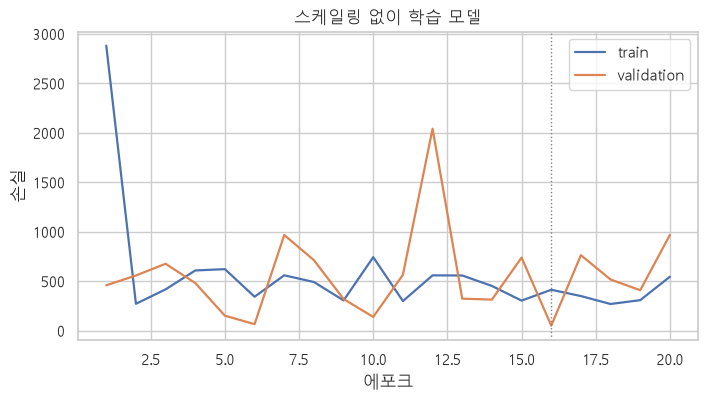

스케일링 없이 학습 모델                AUC 0.5031 정확도 0.6253
AUC 0.50  ---> 0.5에 가까울 수록 무작위 찍기와 다를바 없음!


In [48]:
plot_history(hist_raw, "스케일링 없이 학습 모델")
plt.show()

auc_raw = evaluate("스케일링 없이 학습 모델", model_raw, X_test, y_test)
print(f"AUC {auc_raw:.2f}  ---> 0.5에 가까울 수록 무작위 찍기와 다를바 없음!")

---

### 스케일링 후 학습
> StandardScaler 로 모든 피처를 평균 0, 표준편차 1로 맞춰주기

In [49]:
scaler = StandardScaler().fit(X_fit)

X_fit_s = scaler.transform(X_fit)
X_val_s = scaler.transform(X_val)
X_test_s = scaler.transform(X_test)

print(
    pd.DataFrame({"평균": X_fit_s.mean(axis=0).round(3),
                  "표준편차": X_fit_s.std(axis=0).round(3)}, index=FEATURES)
)

               평균  표준편차
ret_1d       -0.0   1.0
ret_5d        0.0   1.0
ma5_ratio    -0.0   1.0
ma20_ratio   -0.0   1.0
vol20         0.0   1.0
volume_ratio  0.0   1.0
range_pct     0.0   1.0
volume_prev  -0.0   1.0
close_prev   -0.0   1.0


In [50]:
t0 = time.time()

model_scaled = build_model(len(FEATURES))
hist_scaled = model_scaled.fit(
    X_fit_s, y_fit,
    epochs=20,
    batch_size=512,
    validation_data = (X_val_s, y_val),
    shuffle=False,
    verbose = 0
)

print(f"학습 시간 : {time.time() - t0:.0f} 초")
print_history(hist_scaled)

학습 시간 : 3 초
epoch    train_loss          val_loss
    1         0.6526        0.6417
    3         0.6323        0.6258
    5         0.6284        0.6221
    7         0.6266        0.6205
    9         0.6255        0.6195
   11         0.6246        0.6188
   13         0.6239        0.6184
   15         0.6233        0.6181
   17         0.6228        0.6179
   19         0.6223        0.6177


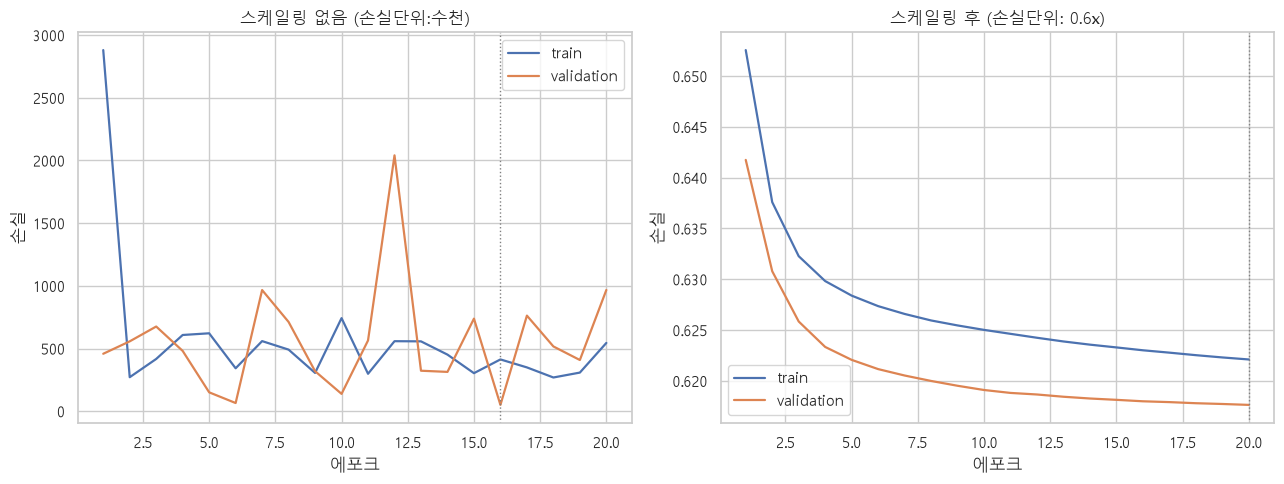

스케일링 없음                      AUC 0.5031 정확도 0.6253
스케일링 후                       AUC 0.6252 정확도 0.6295
AUC 비교 (스케일링 x -> o) : 0.503 -> 0.625


In [52]:
fig, axes = plt.subplots(1, 2, figsize =(13,5))

plot_history(hist_raw, "스케일링 없음 (손실단위:수천)", ax=axes[0])
plot_history(hist_scaled, "스케일링 후 (손실단위: 0.6x)", ax=axes[1])
plt.tight_layout()
plt.show()

auc_raw = evaluate("스케일링 없음", model_raw, X_test, y_test)
auc_scaled = evaluate("스케일링 후", model_scaled, X_test_s, y_test)

print(f"AUC 비교 (스케일링 x -> o) : {auc_raw:.3f} -> {auc_scaled:.3f}")

> 스케일링은 단순히 성능을 조금 올려주는 게 아니라, 신경망 자체가 동작하느냐 마느냐의 문제로 볼 수 있음. \
> 그렇기 때문에 스케일러와 모델은 항상 함께 다뤄야 함!

**히스토리 해석**
|모양|상태|할일|
|---|---|---|
|둘다 내려가는 중|학습이 되는 중|에포크를 늘림|
|둘다 낮고 붙어있음|학습 완료 상태|그대로 사용|
|train은 내려가는데, val은 올라감|과적합|학습 멈춤|
|둘다 높고 내려가지 않음|과소적합, 학습데이터/피처 부족|스케일링 확인->모델키우기->피처추가|
|둘다 크게 튀면서 불안정|학습 불안정(발산)|스케일링 확인->학습률 낮추기|

---
### Dropout 없이 크게 학습 -> 과적합

에포크 : 20 => 60 / 은닉층 256->256->128

In [54]:
t0 = time.time()

model_big = build_model(len(FEATURES), hidden=(256,256,128), dropout=0.0)
print(f"{model_big.count_params():,}개 / 학습 데이터 {len(X_fit):,}행")

hist_big = model_big.fit(
    X_fit_s, y_fit,
    epochs=60,
    batch_size=512,
    validation_data=(X_val_s, y_val),
    shuffle=False,
    verbose = 0
)

print(f"학습 시간 : {time.time() - t0:.0f}초")
print_history(hist_big)

101,377개 / 학습 데이터 55,968행
학습 시간 : 20초
epoch    train_loss          val_loss
    1         0.6468        0.6350
    7         0.6246        0.6194
   13         0.6216        0.6194
   19         0.6186        0.6211
   25         0.6138        0.6240
   31         0.6065        0.6295
   37         0.5966        0.6404
   43         0.5831        0.6534
   49         0.5677        0.6668
   55         0.5502        0.6839


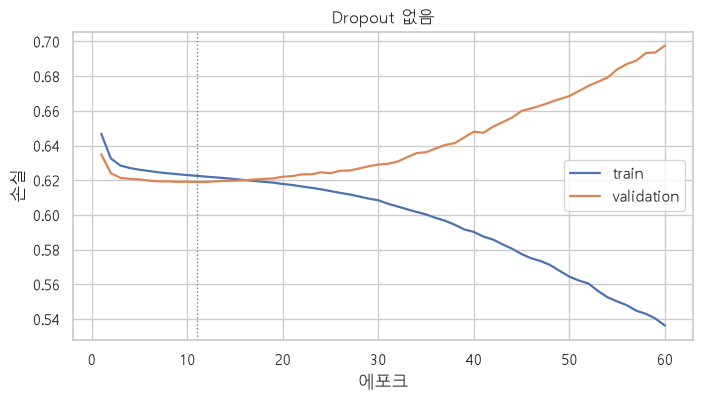

은닉층 키우고 Dropout 없음           AUC 0.5922 정확도 0.6062


0.5921760025453596

In [55]:
plot_history(hist_big, "Dropout 없음")
plt.show()

evaluate("은닉층 키우고 Dropout 없음", model_big, X_test, y_test, scaler)

**과적합 신호 찾기**
- 에포크를 늘리면 train 손실은 계속 내려가는데, val 손실은 어느 지점부터 올라가기 시작함
- 이렇게 두 곡선이 벌어지는 모양이 '과적합'임

---

### Dropout + EarlyStopping 적용
- Dropout(0.3) : 학습 중 뉴런의 30%를 무작위로 끔 -> 특정 뉴런에 의존하지 못하게
- EarlyStopping : patience값 만큼 참고, 이 값이 넘어가도 검증 손실이 나아지지 않으면 멈춤

In [57]:
es = EarlyStopping(
    monitor="val_loss",         # 무엇을 볼 것인가?
    patience=8,                 # 몇번 참을 것인가?
    restore_best_weights=True   # 참기 전 가장 좋았던 시점으로 되돌림
)

t0 = time.time()

model_drop = build_model(len(FEATURES), hidden=(256, 256, 128), dropout= 0.3)
print(f"{model_drop.count_params():,}개 / 학습 데이터 {len(X_fit):,}행")

hist_drop = model_drop.fit(
    X_fit_s, y_fit,
    epochs=60,
    batch_size=512,
    validation_data=(X_val_s, y_val),
    shuffle=False,
    verbose=0,
    callbacks=[es]
)

ran = len(hist_drop.history["loss"])
best = int( np.argmin(hist_drop.history['val_loss'])) + 1

print(f"실행한 에포크 : {ran}  val_loss 최저 에포크 : {best}")

print(f"학습 시간 : {time.time() - t0:.0f}초")
print_history(hist_drop)

101,377개 / 학습 데이터 55,968행
실행한 에포크 : 30  val_loss 최저 에포크 : 22
학습 시간 : 14초
epoch    train_loss          val_loss
    1         0.6506        0.6293
    4         0.6301        0.6194
    7         0.6277        0.6182
   10         0.6258        0.6164
   13         0.6254        0.6164
   16         0.6241        0.6163
   19         0.6239        0.6163
   22         0.6238        0.6155
   25         0.6228        0.6164
   28         0.6222        0.6159


<Axes: title={'center': 'Dropout + EarlyStopping'}, xlabel='에포크', ylabel='손실'>

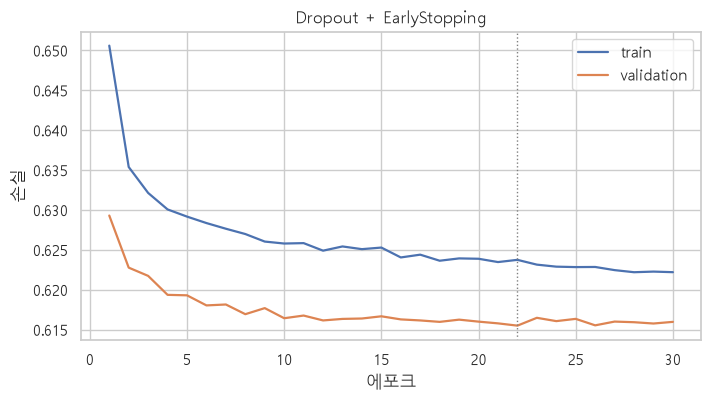

In [58]:
plot_history(hist_drop, "Dropout + EarlyStopping")